## Analysis 2: Antibiotic Resistance Rates (Zhu et al., 2025)

In [77]:

import pandas as pd

# Load study-level data directly from GitHub
data_url = (
    "https://raw.githubusercontent.com/"
    "cjjde05/acne-antibiotic-resistance-analysis/"
    "main/Analysis_2_Zhu_2025/data/"
    "zhu_2025_study_level_resistance.csv"
)

zhu_df = pd.read_csv(data_url)

display(zhu_df.head())
print("Dataset shape:", zhu_df.shape)


,study,collection_period,region,total_isolates,breakpoint_standard,testing_method,levofloxacin,erythromycin,roxithromycin,azithromycin,clarithromycin,clindamycin,tetracycline,doxycycline,minocycline,chloramphenicol,tmp_smx
0,Fan2016,June to August 2014,"China (Chongqing, Sichuan, Yunnan, Shaanxi, Hu...",312,CLSI,Agar dilution,NaN,149.0,NaN,149.0,NaN,NaN,2.0,1.0,0.0,1.0,NaN
1,Mendoza2013,January 2005 to May 2006,Colombia,100,NCCLS,Agar dilution,NaN,35.0,NaN,NaN,NaN,15.0,3.0,9.0,1.0,NaN,NaN
2,Biswal2016,2010 to 2012,India,66,CLSI,E-test,NaN,4.0,NaN,NaN,NaN,0.0,4.0,NaN,0.0,NaN,NaN
3,Sheffer-Levi2020,December 2017 to May 2018,Israel,36,CLSI,E-test,NaN,9.0,NaN,NaN,NaN,6.0,3.0,7.0,4.0,NaN,NaN
4,Nakase2014,2009 to 2010,Japan,69,CLSI,Agar dilution,3.0,16.0,NaN,NaN,16.0,13.0,NaN,3.0,0.0,NaN,NaN


Dataset shape: (23, 17)


In [78]:
# Check total number of isolates
print("Total isolates:", zhu_df["total_isolates"].sum())

# Check missing values
print("\nMissing values by column:")
print(zhu_df.isna().sum())


Total isolates: 2046

Missing values by column:
study                   0
collection_period       2
region                  0
total_isolates          0
breakpoint_standard     0
testing_method          0
levofloxacin           19
erythromycin            3
roxithromycin          21
azithromycin           18
clarithromycin         18
clindamycin             5
tetracycline            8
doxycycline             9
minocycline             9
chloramphenicol        21
tmp_smx                21
dtype: int64


In [79]:

# Calculate resistance rates using available studies

antibiotics = [
    "erythromycin",
    "clindamycin",
    "doxycycline"
]

results = []

for antibiotic in antibiotics:
    available = zhu_df.dropna(subset=[antibiotic])

    total = available["total_isolates"].sum()
    resistant = available[antibiotic].sum()

    rate = (resistant / total) * 100

    results.append({
        "Antibiotic": antibiotic,
        "Studies": len(available),
        "Total Isolates": total,
        "Resistant Isolates": resistant,
        "Resistance Rate (%)": round(rate, 2)
    })

resistance_summary = pd.DataFrame(results)
display(resistance_summary)


,Antibiotic,Studies,Total Isolates,Resistant Isolates,Resistance Rate (%)
0,erythromycin,20,1783,630.0,35.33
1,clindamycin,18,1369,383.0,27.98
2,doxycycline,14,1424,54.0,3.79


In [80]:

# All 11 antibiotics
antibiotics = [
    "levofloxacin", "erythromycin", "roxithromycin",
    "azithromycin", "clarithromycin", "clindamycin",
    "tetracycline", "doxycycline", "minocycline",
    "chloramphenicol", "tmp_smx"
]

results = []

for antibiotic in antibiotics:
    available = zhu_df.dropna(subset=[antibiotic])

    total = available["total_isolates"].sum()
    resistant = available[antibiotic].sum()
    rate = (resistant / total) * 100

    results.append({
        "Antibiotic": antibiotic,
        "Studies": len(available),
        "Total Isolates": total,
        "Resistant Isolates": resistant,
        "Resistance Rate (%)": round(rate, 2)
    })

resistance_summary = pd.DataFrame(results)
display(resistance_summary)


,Antibiotic,Studies,Total Isolates,Resistant Isolates,Resistance Rate (%)
0,levofloxacin,4,308,20.0,6.49
1,erythromycin,20,1783,630.0,35.33
2,roxithromycin,2,191,92.0,48.17
3,azithromycin,5,695,313.0,45.04
4,clarithromycin,5,470,263.0,55.96
5,clindamycin,18,1369,383.0,27.98
6,tetracycline,15,1363,37.0,2.71
7,doxycycline,14,1424,54.0,3.79
8,minocycline,14,1337,21.0,1.57
9,chloramphenicol,2,360,1.0,0.28


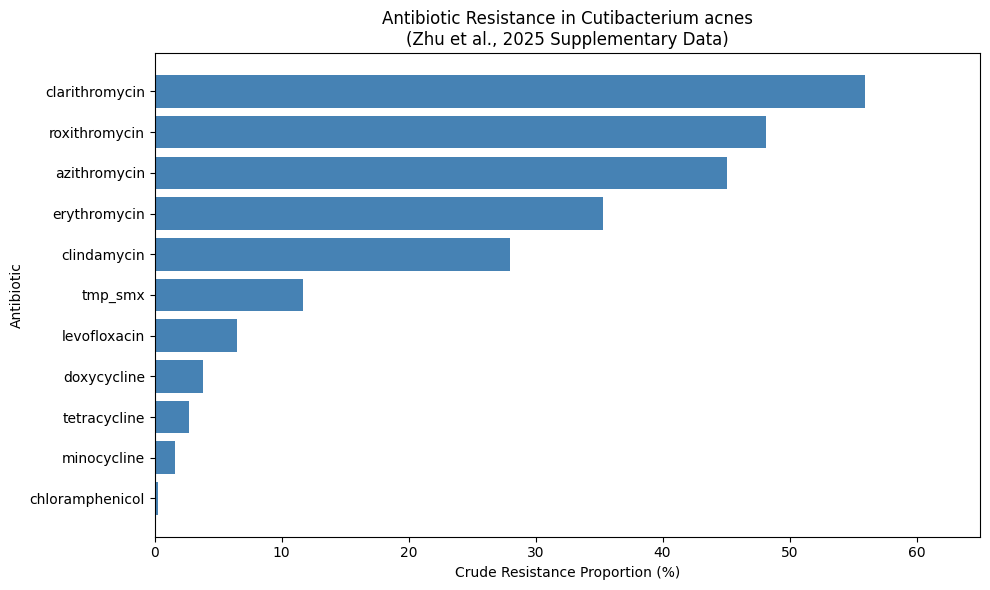

In [81]:

import matplotlib.pyplot as plt

# Sort antibiotics by resistance rate
plot_data = resistance_summary.sort_values(
    "Resistance Rate (%)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Antibiotic"],
    plot_data["Resistance Rate (%)"],
    color="steelblue"
)

plt.xlabel("Crude Resistance Proportion (%)")
plt.ylabel("Antibiotic")
plt.title("Antibiotic Resistance in Cutibacterium acnes\n(Zhu et al., 2025 Supplementary Data)")

plt.xlim(0, 65)
plt.tight_layout()

plt.savefig("zhu_2025_resistance_rates.png", dpi=300)
plt.show()


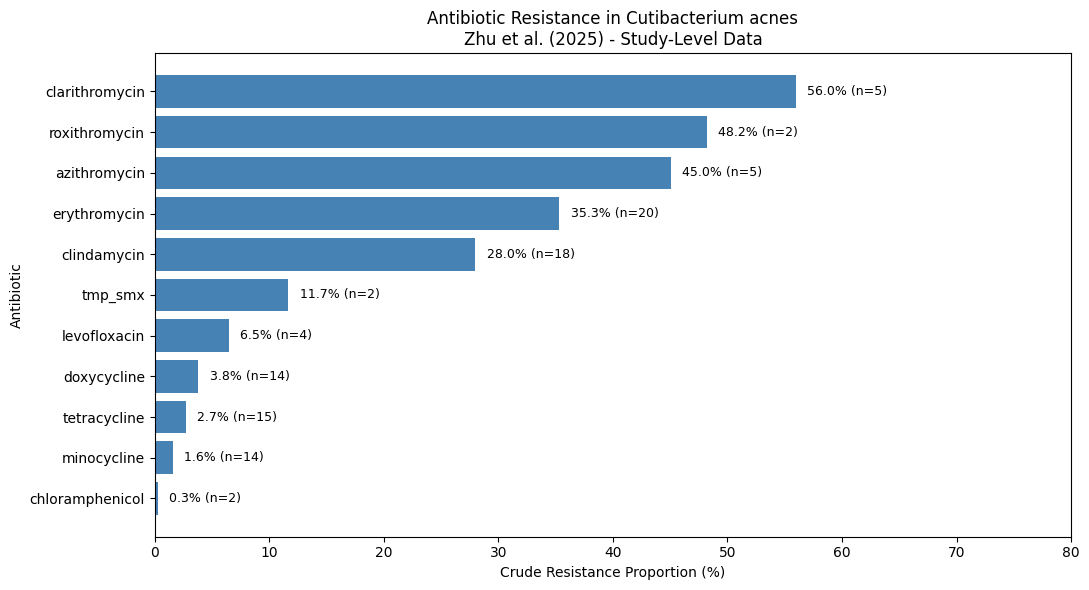

In [82]:

import matplotlib.pyplot as plt

plot_data = resistance_summary.sort_values(
    "Resistance Rate (%)"
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    plot_data["Antibiotic"],
    plot_data["Resistance Rate (%)"],
    color="steelblue"
)

for bar, rate, studies in zip(
    bars,
    plot_data["Resistance Rate (%)"],
    plot_data["Studies"]
):
    plt.text(
        rate + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}% (n={studies})",
        va="center",
        fontsize=9
    )

plt.xlabel("Crude Resistance Proportion (%)")
plt.ylabel("Antibiotic")
plt.title(
    "Antibiotic Resistance in Cutibacterium acnes\n"
    "Zhu et al. (2025) - Study-Level Data"
)

plt.xlim(0, 80)
plt.tight_layout()

plt.savefig(
    "zhu_2025_resistance_rates_labeled.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [83]:

# Select studies with clindamycin data
clinda_studies = zhu_df.dropna(
    subset=["clindamycin"]
).copy()

# Calculate resistance percentage for each study
clinda_studies["resistance_rate"] = (
    clinda_studies["clindamycin"]
    / clinda_studies["total_isolates"]
    * 100
)

# Display study-level results
display(
    clinda_studies[
        ["study", "region", "total_isolates",
         "clindamycin", "resistance_rate"]
    ].sort_values("resistance_rate", ascending=False)
)


,study,region,total_isolates,clindamycin,resistance_rate
13,Ma2021,China (Shanghai),44,25.0,56.818182
9,Luk2013,China (Hong Kong),86,46.0,53.488372
18,Aoki2019,Japan,34,15.0,44.117647
6,Aoki2021,Japan,127,55.0,43.307087
5,Koyanagi2023,Japan,64,27.0,42.187500
15,Tang2024,China (Yunnan),139,55.0,39.568345
11,Ma2016,China (Shanghai),69,23.0,33.333333
12,Tang2018,China (Guangdong),156,45.0,28.846154
22,Zhang2019,China (Shanghai),63,18.0,28.571429
17,OzelKaya2021,Turkey,57,13.0,22.807018


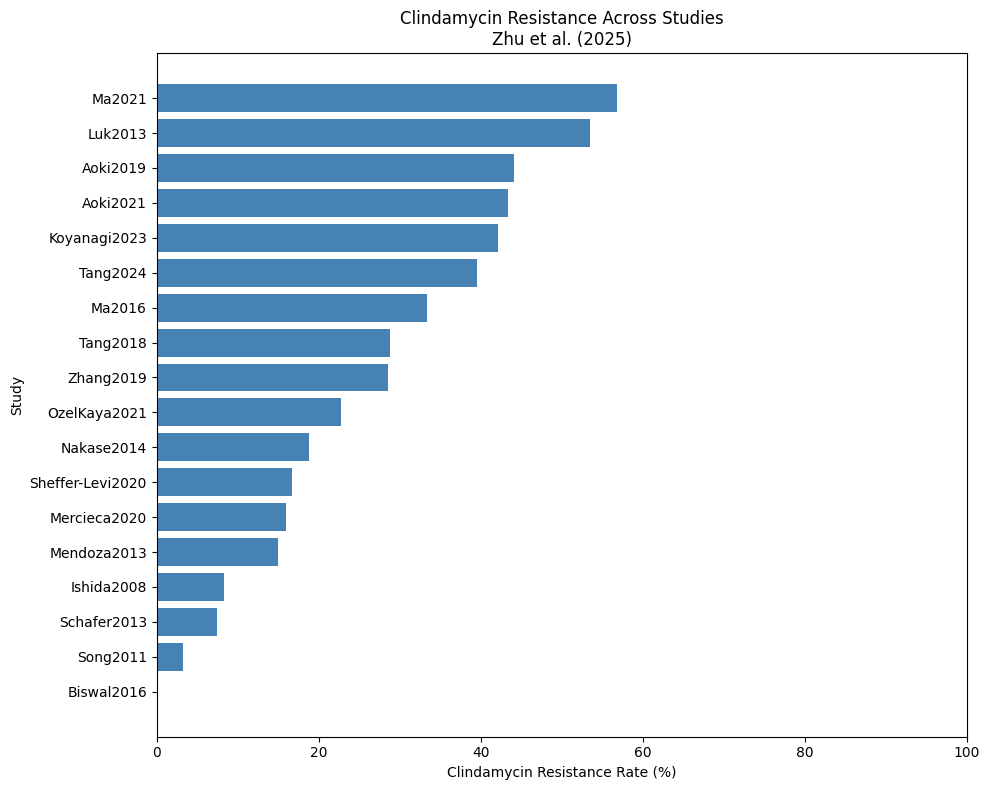

In [84]:

import matplotlib.pyplot as plt

# Sort studies by resistance rate
plot_data = clinda_studies.sort_values("resistance_rate")

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["study"],
    plot_data["resistance_rate"],
    color="steelblue"
)

plt.xlabel("Clindamycin Resistance Rate (%)")
plt.ylabel("Study")
plt.title(
    "Clindamycin Resistance Across Studies\n"
    "Zhu et al. (2025)"
)

plt.xlim(0, 100)
plt.tight_layout()

plt.savefig(
    "clindamycin_study_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [85]:

# Summary statistics for clindamycin resistance

rates = clinda_studies["resistance_rate"]

print("Number of studies:", len(rates))
print("Minimum resistance rate:", round(rates.min(), 2), "%")
print("Maximum resistance rate:", round(rates.max(), 2), "%")
print("Mean resistance rate:", round(rates.mean(), 2), "%")
print("Median resistance rate:", round(rates.median(), 2), "%")
print("Standard deviation:", round(rates.std(), 2))


Number of studies: 18
Minimum resistance rate: 0.0 %
Maximum resistance rate: 56.82 %
Mean resistance rate: 26.59 %
Median resistance rate: 25.69 %
Standard deviation: 17.25


### Result (using the data above):
Among 18 studies reporting clindamycin resistance, resistance rates ranged from 0% to 56.82%. The mean resistance rate was 26.59%, with a median of 25.69% and a standard deviation of 17.25 percentage points. These findings show substantial variation in reported clindamycin resistance across studies.

In [86]:

clinda_studies[
    ["study", "region", "total_isolates",
     "clindamycin", "resistance_rate"]
].to_csv(
    "clindamycin_study_resistance.csv",
    index=False
)

print("CSV file saved successfully!")


CSV file saved successfully!


In [87]:

# Count clindamycin studies by region
region_counts = (
    clinda_studies["region"]
    .value_counts()
    .reset_index()
)

region_counts.columns = ["Region", "Number of Studies"]

display(region_counts)


,Region,Number of Studies
0,Japan,5
1,China (Shanghai),3
2,India,1
3,Colombia,1
4,Israel,1
5,South Korea,1
6,China (Hong Kong),1
7,Chile,1
8,China (Guangdong),1
9,China (Yunnan),1


In [88]:

# Create a country column
clinda_studies["country"] = clinda_studies["region"].copy()

# Group Chinese regions together
clinda_studies.loc[
    clinda_studies["region"].str.startswith("China"),
    "country"
] = "China"

# Count studies by country
country_counts = (
    clinda_studies["country"]
    .value_counts()
    .reset_index()
)

country_counts.columns = ["Country", "Number of Studies"]

display(country_counts)


,Country,Number of Studies
0,China,6
1,Japan,5
2,Colombia,1
3,Israel,1
4,India,1
5,South Korea,1
6,Chile,1
7,Turkey,1
8,Malta,1


In [89]:

# Calculate resistance rates by country
country_summary = (
    clinda_studies
    .groupby("country")
    .agg(
        Studies=("study", "count"),
        Total_Isolates=("total_isolates", "sum"),
        Resistant_Isolates=("clindamycin", "sum")
    )
    .reset_index()
)

country_summary["Resistance_Rate"] = (
    country_summary["Resistant_Isolates"]
    / country_summary["Total_Isolates"]
    * 100
).round(2)

country_summary = country_summary.sort_values(
    "Resistance_Rate",
    ascending=False
)

display(country_summary)


,country,Studies,Total_Isolates,Resistant_Isolates,Resistance_Rate
1,China,6,557,212.0,38.06
5,Japan,5,342,114.0,33.33
8,Turkey,1,57,13.0,22.81
4,Israel,1,36,6.0,16.67
6,Malta,1,100,16.0,16.00
2,Colombia,1,100,15.0,15.00
0,Chile,1,80,6.0,7.50
7,South Korea,1,31,1.0,3.23
3,India,1,66,0.0,0.00


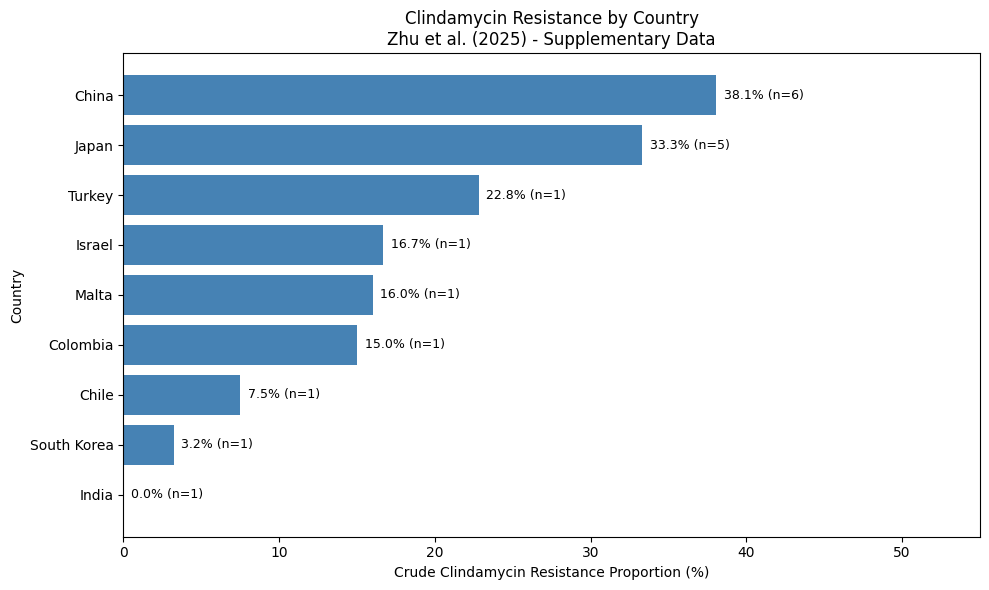

In [90]:

import matplotlib.pyplot as plt

plot_data = country_summary.sort_values("Resistance_Rate")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data["country"],
    plot_data["Resistance_Rate"],
    color="steelblue"
)

for bar, rate, studies in zip(
    bars,
    plot_data["Resistance_Rate"],
    plot_data["Studies"]
):
    plt.text(
        rate + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}% (n={studies})",
        va="center",
        fontsize=9
    )

plt.xlabel("Crude Clindamycin Resistance Proportion (%)")
plt.ylabel("Country")
plt.title(
    "Clindamycin Resistance by Country\n"
    "Zhu et al. (2025) - Supplementary Data"
)

plt.xlim(0, 55)
plt.tight_layout()

plt.savefig(
    "clindamycin_country_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [91]:

# Save antibiotic resistance summary
resistance_summary.to_csv(
    "zhu_2025_antibiotic_summary.csv",
    index=False
)

# Save country-level comparison
country_summary.to_csv(
    "clindamycin_country_comparison.csv",
    index=False
)

print("Both CSV files saved successfully!")


Both CSV files saved successfully!
